In [ ]:
!pip install ultralytics -q

import torch
import ultralytics

# перевіряю відеокарту і записую версії бібліотек для звіту
print("GPU є:", torch.cuda.is_available())
print("Відеокарта:", torch.cuda.get_device_name(0))
print("ultralytics:", ultralytics.__version__)
print("torch:", torch.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU є: True
Відеокарта: Tesla T4
ultralytics: 8.4.215
torch: 2.14.1+cu130


In [ ]:
import os

# архів датасету Penn-Fudan з сайту університету Пенсільванії
!wget -q https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip

# розпакування архіву в поточну папку
!unzip -q -o PennFudanPed.zip

# кількість файлів у кожній папці датасету
root = "PennFudanPed"
for folder in ["PNGImages", "PedMasks", "Annotation"]:
    print(folder, len(os.listdir(os.path.join(root, folder))))


PNGImages 170
PedMasks 170
Annotation 170


In [ ]:
import os
import random
import shutil
import numpy as np
from PIL import Image

root = "PennFudanPed"
out = "datasets/pennfudan"

# список фото у фіксованому порядку, потім перемішування з seed 42
names = sorted(os.listdir(os.path.join(root, "PNGImages")))
random.Random(42).shuffle(names)

# розбиття 120 / 25 / 25
splits = {
    "train": names[:120],
    "val": names[120:145],
    "test": names[145:],
}

for split, files in splits.items():
    os.makedirs(f"{out}/images/{split}", exist_ok=True)
    os.makedirs(f"{out}/labels/{split}", exist_ok=True)
    box_count = 0

    for name in files:
        base = name.replace(".png", "")
        mask = np.array(Image.open(os.path.join(root, "PedMasks", base + "_mask.png")))
        h, w = mask.shape

        lines = []
        for pid in np.unique(mask):
            # значення 0 у масці це фон
            if pid == 0:
                continue

            # найменший прямокутник навколо пікселів однієї людини
            ys, xs = np.where(mask == pid)
            x1, x2 = xs.min(), xs.max() + 1
            y1, y2 = ys.min(), ys.max() + 1

            # формат YOLO: клас, центр x, центр y, ширина, висота (у частках від розміру фото)
            cx = (x1 + x2) / 2 / w
            cy = (y1 + y2) / 2 / h
            bw = (x2 - x1) / w
            bh = (y2 - y1) / h
            lines.append(f"0 {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}")

        # копія фото та відповідний текстовий файл розмітки
        shutil.copy(os.path.join(root, "PNGImages", name), f"{out}/images/{split}/{name}")
        with open(f"{out}/labels/{split}/{base}.txt", "w") as f:
            f.write("\n".join(lines))
        box_count += len(lines)

    print(f"{split}: фото {len(files)}, рамок {box_count}")

# приклад файлу розмітки
example = os.listdir(f"{out}/labels/train")[0]
print()
print("Приклад:", example)
print(open(f"{out}/labels/train/{example}").read())

train: фото 120, рамок 291
val: фото 25, рамок 67
test: фото 25, рамок 65

Приклад: FudanPed00055.txt
0 0.543590 0.636937 0.333333 0.636036


names:
  0: person
path: /content/datasets/pennfudan
test: images/test
train: images/train
val: images/val



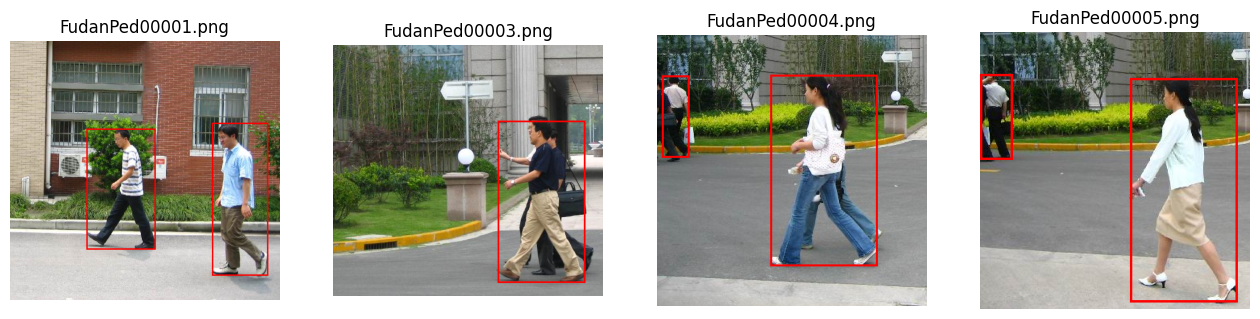

In [ ]:
import os
import yaml
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

out = "datasets/pennfudan"

# конфігурація датасету для YOLO: шляхи до частин і назви класів
config = {
    "path": "/content/datasets/pennfudan",
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "person"},
}
with open("pennfudan.yaml", "w") as f:
    yaml.dump(config, f, allow_unicode=True)

print(open("pennfudan.yaml").read())

# рамки з файлів розмітки на перших чотирьох навчальних фото
files = sorted(os.listdir(f"{out}/images/train"))[:4]
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, name in zip(axes, files):
    img = Image.open(f"{out}/images/train/{name}").convert("RGB")
    w, h = img.size
    draw = ImageDraw.Draw(img)

    for line in open(f"{out}/labels/train/{name.replace('.png', '.txt')}").read().splitlines():
        _, cx, cy, bw, bh = map(float, line.split())
        draw.rectangle(
            [(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h],
            outline="red", width=3,
        )

    ax.imshow(img)
    ax.set_title(name)
    ax.axis("off")

plt.show()

In [ ]:
import shutil
from ultralytics import YOLO
from google.colab import files

# попередньо навчена модель YOLOv8n
model_n = YOLO("yolov8n.pt")

# навчання: однакові умови для всіх моделей (imgsz 640, 50 епох, batch 16, seed 42)
model_n.train(
    data="pennfudan.yaml",
    imgsz=640,
    epochs=50,
    batch=16,
    seed=42,
    deterministic=True,
    workers=2,
    project="runs",
    name="yolov8n",
    exist_ok=True,
)

# архів із результатами навчання для збереження на комп'ютер
shutil.make_archive("yolov8n_results", "zip", "runs/yolov8n")
files.download("yolov8n_results.zip")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=pennfudan.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, over

FileNotFoundError: [Errno 2] No such file or directory: 'runs/yolov8n'

In [ ]:
import shutil
from google.colab import files

# папка з результатами навчання YOLOv8n у структурі Ultralytics
shutil.make_archive("yolov8n_results", "zip", "runs/detect/runs/yolov8n")
files.download("yolov8n_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from ultralytics import YOLO
from google.colab import files

# попередньо навчена модель YOLOv8s
model_s = YOLO("yolov8s.pt")

# навчання в тих самих умовах, що й для YOLOv8n
model_s.train(
    data="pennfudan.yaml",
    imgsz=640,
    epochs=50,
    batch=16,
    seed=42,
    deterministic=True,
    workers=2,
    project="runs",
    name="yolov8s",
    exist_ok=True,
)

# папка результатів визначається автоматично та пакується в архів
save_dir = str(model_s.trainer.save_dir)
print("Результати в папці:", save_dir)
shutil.make_archive("yolov8s_results", "zip", save_dir)
files.download("yolov8s_results.zip")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=pennfudan.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, over

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO

# найкращі ваги обох моделей
paths = {
    "YOLOv8n": "/content/runs/detect/runs/yolov8n/weights/best.pt",
    "YOLOv8s": "/content/runs/detect/runs/yolov8s/weights/best.pt",
}

test_metrics = {}

for name, path in paths.items():
    model = YOLO(path)

    # оцінка на тестовій частині датасету, ті самі умови для обох моделей
    result = model.val(
        data="pennfudan.yaml",
        split="test",
        imgsz=640,
        batch=16,
        plots=False,
        project="runs",
        name="test_" + name,
        exist_ok=True,
    )

    test_metrics[name] = {
        "map50": result.box.map50,
        "map50_95": result.box.map,
        "precision": result.box.mp,
        "recall": result.box.mr,
    }

print()
for name, m in test_metrics.items():
    print(f"{name} | mAP@0.5: {m['map50']:.3f} | mAP@0.5:0.95: {m['map50_95']:.3f} | P: {m['precision']:.3f} | R: {m['recall']:.3f}")



Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3107.5±769.7 MB/s, size: 322.7 KB)
val: Scanning /content/datasets/pennfudan/labels/test.cache... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 5.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8it/s 0.7s
                   all         25         65      0.919      0.892      0.936      0.778
Speed: 1.0ms preprocess, 5.7ms inference, 0.0ms loss, 1.5ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3155.8±446.2 MB/s, size: 320.9 KB)
val: Scanning /content/datasets/pennfudan/labels/test.cache... 25 

In [ ]:
import os
import time
import numpy as np
import pandas as pd
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops
from google.colab import files

weights = {
    "YOLOv8n": "/content/runs/detect/runs/yolov8n/weights/best.pt",
    "YOLOv8s": "/content/runs/detect/runs/yolov8s/weights/best.pt",
}

# одне тестове фото для вимірювання швидкості
test_dir = "/content/datasets/pennfudan/images/test"
sample = os.path.join(test_dir, sorted(os.listdir(test_dir))[0])

# параметри та FLOPs для моделі зі злитими шарами, як у логах валідації
info = {}
for name, path in weights.items():
    m = YOLO(path)
    m.fuse()
    params = sum(p.numel() for p in m.model.parameters()) / 1e6
    flops = get_flops(m.model, imgsz=640)
    info[name] = (params, flops)
    print(name, "| параметри (М):", round(params, 2), "| FLOPs (Г):", round(flops, 1))


def measure(models_dict, device, runs, rounds, warmup):
    # прогрів, потім заміри по колу, результат як медіана в мілісекундах
    times = {n: [] for n in models_dict}
    for m in models_dict.values():
        for _ in range(warmup):
            m.predict(sample, imgsz=640, device=device, verbose=False)

    for _ in range(rounds):
        for n, m in models_dict.items():
            start = time.time()
            for _ in range(runs):
                m.predict(sample, imgsz=640, device=device, verbose=False)
            times[n].append((time.time() - start) / runs * 1000)

    return {n: float(np.median(t)) for n, t in times.items()}


# окремі екземпляри моделей для GPU і для CPU
gpu_models = {n: YOLO(p) for n, p in weights.items()}
cpu_models = {n: YOLO(p) for n, p in weights.items()}

lat_gpu = measure(gpu_models, 0, runs=30, rounds=7, warmup=30)
lat_cpu = measure(cpu_models, "cpu", runs=10, rounds=3, warmup=3)

# підсумкова таблиця за шаблоном лаби
rows = []
for name, path in weights.items():
    rows.append({
        "Модель": name,
        "imgsz": 640,
        "Параметри (М)": round(info[name][0], 2),
        "FLOPs (Г)": round(info[name][1], 1),
        "mAP@0.5": round(test_metrics[name]["map50"], 3),
        "mAP@0.5:0.95": round(test_metrics[name]["map50_95"], 3),
        "Latency GPU (мс)": round(lat_gpu[name], 1),
        "Latency CPU (мс)": round(lat_cpu[name], 1),
        "FPS (GPU)": round(1000 / lat_gpu[name], 1),
        "FPS (CPU)": round(1000 / lat_cpu[name], 1),
        "Розмір ваг (МБ)": round(os.path.getsize(path) / 1024 / 1024, 1),
    })

yolo_table = pd.DataFrame(rows)
print()
print(yolo_table.to_string(index=False))

# збереження таблиці на комп'ютер
yolo_table.to_csv("yolo_comparison_table.csv", index=False)
files.download("yolo_comparison_table.csv")

Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
YOLOv8n | параметри (М): 3.13 | FLOPs (Г): 8.6
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
YOLOv8s | параметри (М): 11.13 | FLOPs (Г): 28.4

 Модель  imgsz  Параметри (М)  FLOPs (Г)  mAP@0.5  mAP@0.5:0.95  Latency GPU (мс)  Latency CPU (мс)  FPS (GPU)  FPS (CPU)  Розмір ваг (МБ)
YOLOv8n    640           3.13        8.6    0.936         0.778              18.8              89.3       53.1       11.2              6.2
YOLOv8s    640          11.13       28.4    0.945         0.784              16.6             249.6       60.2        4.0             21.5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

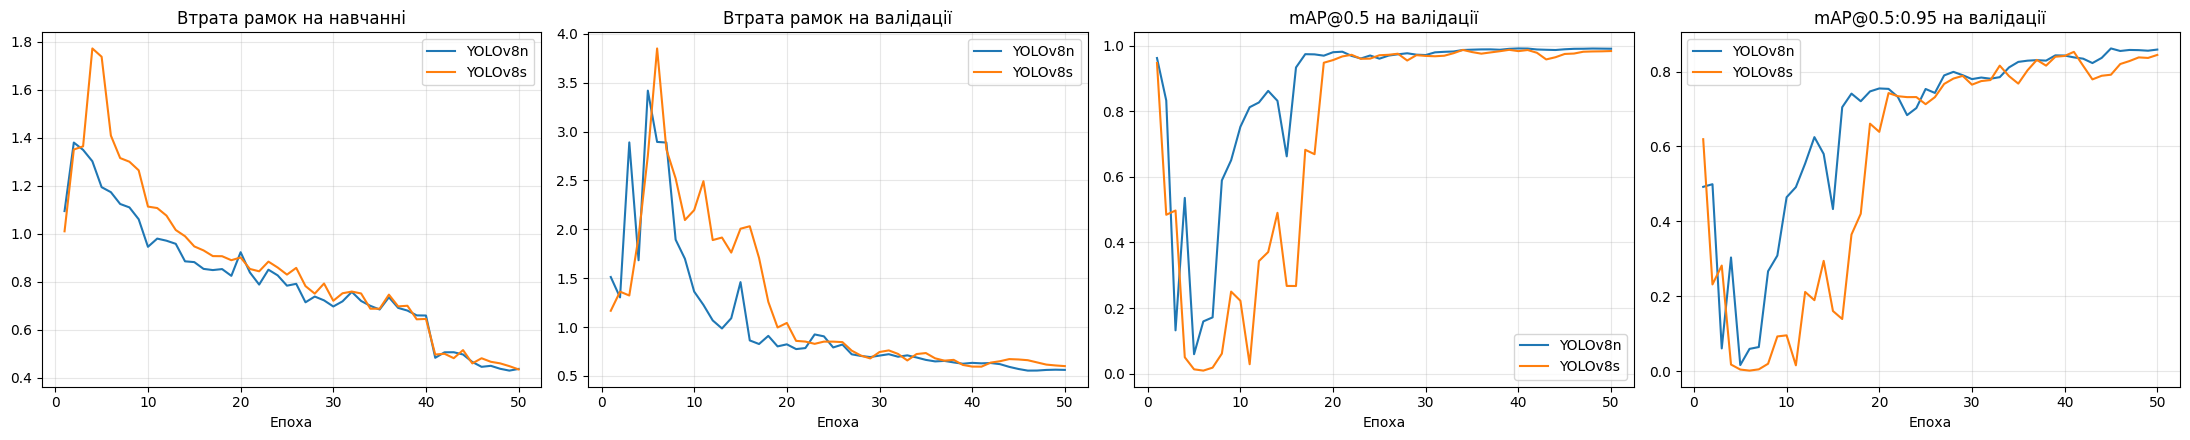

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

base = "/content/runs/detect/runs"
logs = {}
for name in ["yolov8n", "yolov8s"]:
    df = pd.read_csv(f"{base}/{name}/results.csv")
    # у назвах колонок бувають зайві пробіли
    df.columns = [c.strip() for c in df.columns]
    logs[name.replace("yolov8", "YOLOv8")] = df

# колонки для графіків: заголовок і назва колонки в results.csv
plots = [
    ("Втрата рамок на навчанні", "train/box_loss"),
    ("Втрата рамок на валідації", "val/box_loss"),
    ("mAP@0.5 на валідації", "metrics/mAP50(B)"),
    ("mAP@0.5:0.95 на валідації", "metrics/mAP50-95(B)"),
]

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, (title, col) in zip(axes, plots):
    for name, df in logs.items():
        ax.plot(df["epoch"], df[col], label=name)
    ax.set_title(title)
    ax.set_xlabel("Епоха")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("yolo_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# збереження графіка на комп'ютер
files.download("yolo_curves.png")

In [ ]:
import os
import numpy as np
import pandas as pd
from ultralytics import YOLO
from google.colab import files

img_dir = "/content/datasets/pennfudan/images/test"
lbl_dir = "/content/datasets/pennfudan/labels/test"

weights = {
    "YOLOv8n": "/content/runs/detect/runs/yolov8n/weights/best.pt",
    "YOLOv8s": "/content/runs/detect/runs/yolov8s/weights/best.pt",
}


def box_iou(a, b):
    # IoU між кожною парою рамок формату xyxy
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def read_gt(path, w, h):
    # реальні рамки з файлу розмітки: з часток у пікселі, формат xyxy
    boxes = []
    for line in open(path).read().splitlines():
        if not line.strip():
            continue
        _, cx, cy, bw, bh = map(float, line.split())
        boxes.append([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h])
    return np.array(boxes).reshape(-1, 4)


summary = []
errors_log = {}

for name, path in weights.items():
    model = YOLO(path)
    tp = fp = fn = gt_total = 0
    errors_log[name] = []

    for img_name in sorted(os.listdir(img_dir)):
        res = model.predict(os.path.join(img_dir, img_name), imgsz=640, conf=0.25, device=0, verbose=False)[0]
        h, w = res.orig_shape

        gt = read_gt(os.path.join(lbl_dir, img_name.replace(".png", ".txt")), w, h)
        pred = res.boxes.xyxy.cpu().numpy()
        conf = res.boxes.conf.cpu().numpy()

        # зіставлення: передбачення за спаданням упевненості, кожна реальна рамка лише раз
        matched = set()
        img_tp = 0
        if len(pred) and len(gt):
            ious = box_iou(pred, gt)
            for i in np.argsort(-conf):
                best = int(np.argmax(ious[i]))
                if ious[i, best] >= 0.5 and best not in matched:
                    matched.add(best)
                    img_tp += 1

        img_fp = len(pred) - img_tp
        img_fn = len(gt) - img_tp
        tp += img_tp
        fp += img_fp
        fn += img_fn
        gt_total += len(gt)

        if img_fp or img_fn:
            errors_log[name].append((img_name, img_fp, img_fn))

    summary.append({
        "Модель": name,
        "Реальних рамок": gt_total,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": round(tp / (tp + fp), 3),
        "Recall": round(tp / (tp + fn), 3),
    })

fp_table = pd.DataFrame(summary)
print(fp_table.to_string(index=False))

# фото, на яких була хоча б одна помилка
for name, errs in errors_log.items():
    print()
    print(name, "- фото з помилками:", len(errs))
    for img_name, e_fp, e_fn in errs:
        print("  ", img_name, "| FP:", e_fp, "| FN:", e_fn)

# збереження таблиці на комп'ютер
fp_table.to_csv("fp_fn_table.csv", index=False)
files.download("fp_fn_table.csv")

 Модель  Реальних рамок  TP  FP  FN  Precision  Recall
YOLOv8n              65  55   3  10      0.948   0.846
YOLOv8s              65  55   4  10      0.932   0.846

YOLOv8n - фото з помилками: 9
   FudanPed00029.png | FP: 1 | FN: 0
   FudanPed00057.png | FP: 1 | FN: 0
   FudanPed00058.png | FP: 0 | FN: 2
   FudanPed00063.png | FP: 0 | FN: 3
   FudanPed00071.png | FP: 0 | FN: 1
   PennPed00034.png | FP: 0 | FN: 1
   PennPed00035.png | FP: 0 | FN: 1
   PennPed00056.png | FP: 0 | FN: 2
   PennPed00078.png | FP: 1 | FN: 0

YOLOv8s - фото з помилками: 10
   FudanPed00007.png | FP: 1 | FN: 0
   FudanPed00029.png | FP: 1 | FN: 0
   FudanPed00057.png | FP: 1 | FN: 0
   FudanPed00058.png | FP: 0 | FN: 2
   FudanPed00063.png | FP: 0 | FN: 3
   PennPed00034.png | FP: 0 | FN: 1
   PennPed00035.png | FP: 1 | FN: 1
   PennPed00056.png | FP: 0 | FN: 1
   PennPed00066.png | FP: 0 | FN: 1
   PennPed00090.png | FP: 0 | FN: 1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

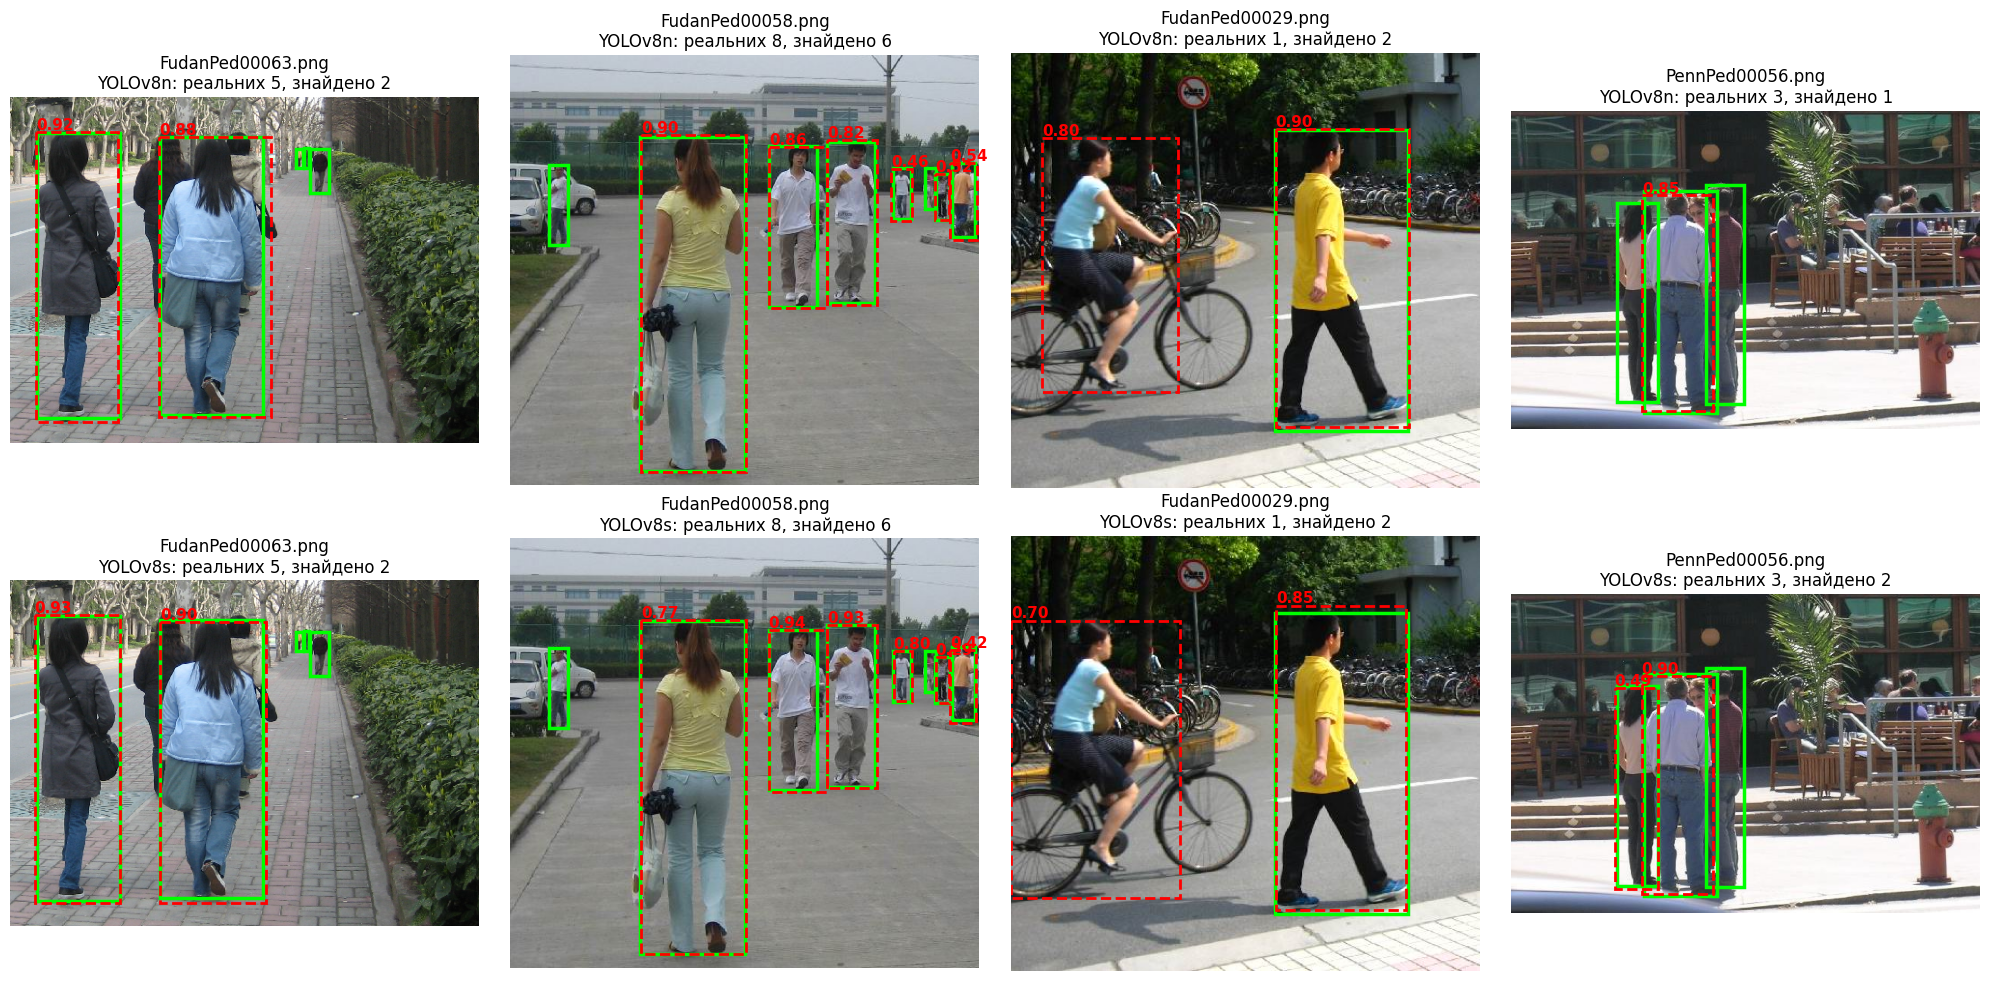

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO
from google.colab import files

img_dir = "/content/datasets/pennfudan/images/test"
lbl_dir = "/content/datasets/pennfudan/labels/test"

models = {
    "YOLOv8n": YOLO("/content/runs/detect/runs/yolov8n/weights/best.pt"),
    "YOLOv8s": YOLO("/content/runs/detect/runs/yolov8s/weights/best.pt"),
}

# фото, на яких помилялися обидві моделі
photos = ["FudanPed00063.png", "FudanPed00058.png", "FudanPed00029.png", "PennPed00056.png"]

fig, axes = plt.subplots(2, len(photos), figsize=(5 * len(photos), 10))

for col, photo in enumerate(photos):
    img = Image.open(os.path.join(img_dir, photo)).convert("RGB")
    w, h = img.size

    # реальні рамки з файлу розмітки: ліва верхня точка, ширина, висота
    gt = []
    for line in open(os.path.join(lbl_dir, photo.replace(".png", ".txt"))).read().splitlines():
        _, cx, cy, bw, bh = map(float, line.split())
        gt.append([(cx - bw / 2) * w, (cy - bh / 2) * h, bw * w, bh * h])

    for row, (name, model) in enumerate(models.items()):
        res = model.predict(os.path.join(img_dir, photo), imgsz=640, conf=0.25, device=0, verbose=False)[0]
        ax = axes[row, col]
        ax.imshow(img)

        # реальні рамки зеленим
        for x, y, bw, bh in gt:
            ax.add_patch(patches.Rectangle((x, y), bw, bh, fill=False, edgecolor="lime", linewidth=2.5))

        # рамки моделі червоним пунктиром з упевненістю
        for box, c in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy()):
            x1, y1, x2, y2 = box
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=2, linestyle="--"))
            ax.text(x1, y1 - 3, f"{c:.2f}", color="red", fontsize=11, fontweight="bold")

        ax.set_title(f"{photo}\n{name}: реальних {len(gt)}, знайдено {len(res.boxes)}")
        ax.axis("off")

plt.tight_layout()
plt.savefig("yolo_errors.png", dpi=130, bbox_inches="tight")
plt.show()

# збереження картинки на комп'ютер
files.download("yolo_errors.png")

In [ ]:
import os
from google.colab import files

# вибір файлів з комп'ютера: фото з людьми та коротке відео
uploaded = files.upload()

os.makedirs("my_media", exist_ok=True)
for file_name in uploaded:
    os.replace(file_name, os.path.join("my_media", file_name))

print("Завантажено файлів:", len(os.listdir("my_media")))
print(os.listdir("my_media"))


Saving 4079656-hd_1920_1080_30fps.mp4 to 4079656-hd_1920_1080_30fps.mp4
Saving 4.jpg to 4.jpg
Saving 3.jpg to 3.jpg
Saving 2.jpg to 2.jpg
Saving 1.jpg to 1.jpg
Завантажено файлів: 5
['2.jpg', '4.jpg', '1.jpg', '4079656-hd_1920_1080_30fps.mp4', '3.jpg']


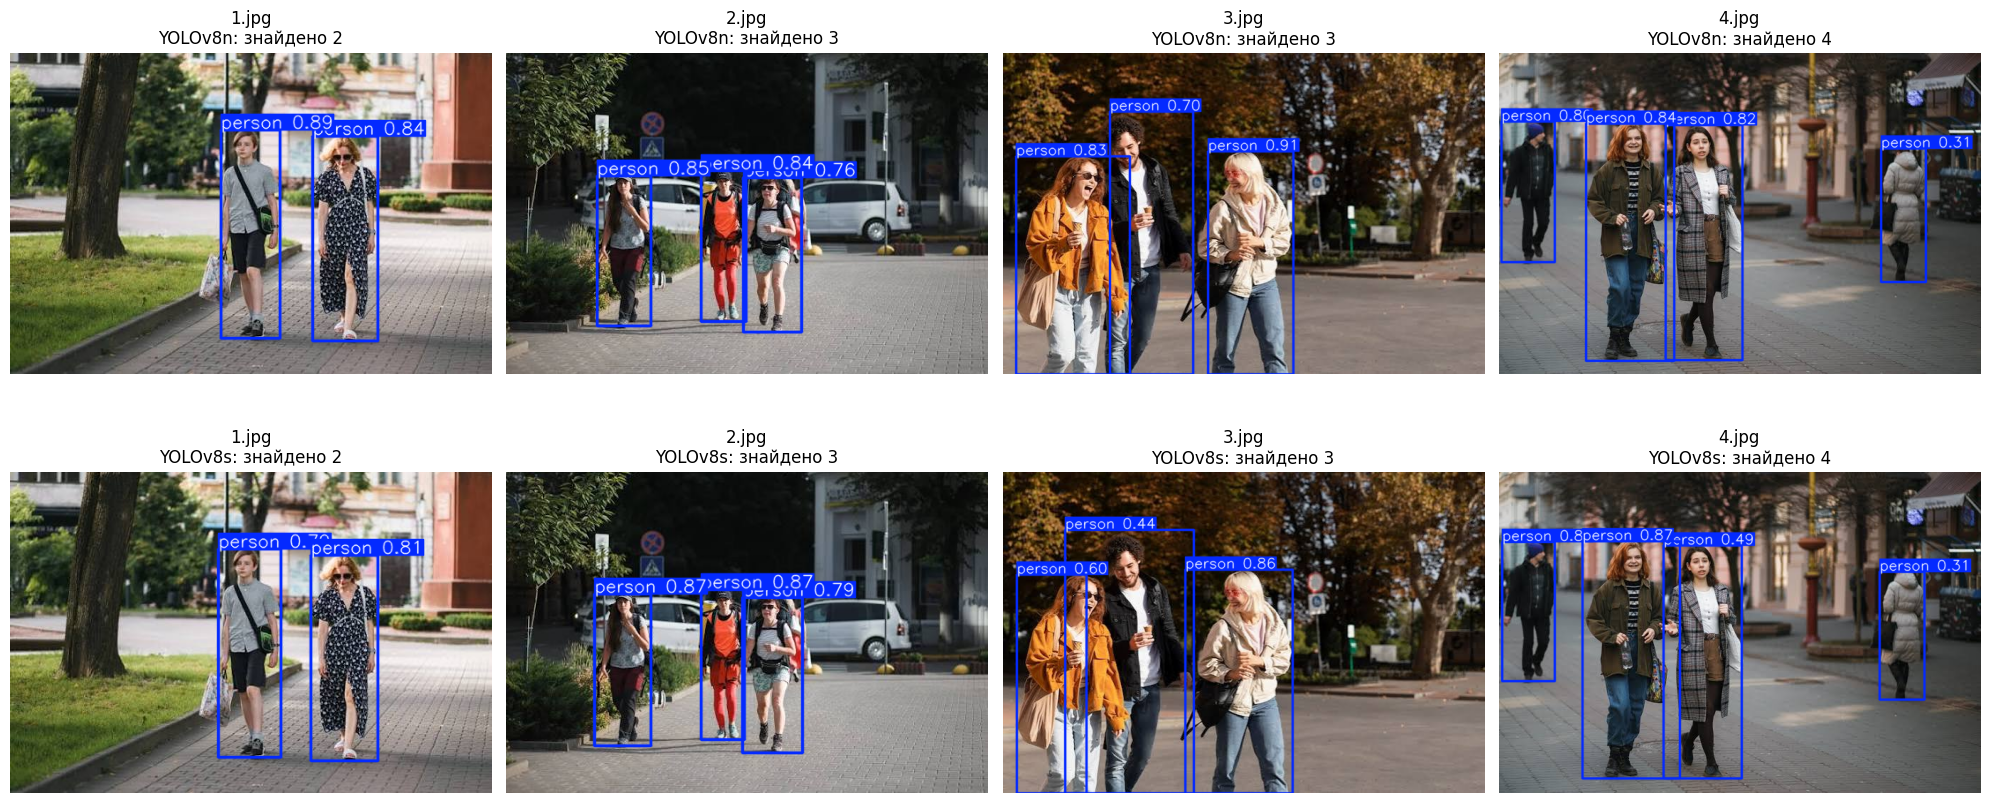

Кадрів оброблено: 180 | fps: 30.0
YOLOv8n: у середньому людей на кадр: 1.60
YOLOv8s: у середньому людей на кадр: 1.70
GIF збережено, кадрів: 60 | розмір, МБ: 9.5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
from google.colab import files

models = {
    "YOLOv8n": YOLO("/content/runs/detect/runs/yolov8n/weights/best.pt"),
    "YOLOv8s": YOLO("/content/runs/detect/runs/yolov8s/weights/best.pt"),
}

media = "my_media"
photos = sorted(f for f in os.listdir(media) if f.lower().endswith((".jpg", ".jpeg", ".png")))
video_name = [f for f in os.listdir(media) if f.lower().endswith(".mp4")][0]

# сітка фото: верхній ряд YOLOv8n, нижній YOLOv8s
fig, axes = plt.subplots(2, len(photos), figsize=(5 * len(photos), 9))
for col, photo in enumerate(photos):
    for row, (name, model) in enumerate(models.items()):
        res = model.predict(os.path.join(media, photo), imgsz=640, conf=0.25, device=0, verbose=False)[0]
        axes[row, col].imshow(res.plot()[:, :, ::-1])
        axes[row, col].set_title(f"{photo}\n{name}: знайдено {len(res.boxes)}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig("my_detections.png", dpi=130, bbox_inches="tight")
plt.show()

# параметри відео: перші 6 секунд, вихідна ширина 960 пікселів
cap = cv2.VideoCapture(os.path.join(media, video_name))
fps = cap.get(cv2.CAP_PROP_FPS)
src_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
src_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
max_frames = int(fps * 6)
out_w = 960
out_h = int(src_h * out_w / src_w)

# кадри відео зчитуються один раз і використовуються для обох моделей
frames = []
while len(frames) < max_frames:
    ok, frame = cap.read()
    if not ok:
        break
    frames.append(frame)
cap.release()
print("Кадрів оброблено:", len(frames), "| fps:", round(fps, 1))

annotated = {}
for name, model in models.items():
    writer = cv2.VideoWriter(f"video_{name.lower()}.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (out_w, out_h))
    shown = []
    people = 0

    for frame in frames:
        res = model.predict(frame, imgsz=640, conf=0.25, device=0, verbose=False)[0]
        people += len(res.boxes)
        small = cv2.resize(res.plot(), (out_w, out_h))
        writer.write(small)
        shown.append(small)

    writer.release()
    annotated[name] = shown
    print(f"{name}: у середньому людей на кадр: {people / len(frames):.2f}")

# GIF: кожен третій кадр, зліва YOLOv8n, справа YOLOv8s
gif_frames = []
for i in range(0, len(frames), 3):
    left = cv2.resize(annotated["YOLOv8n"][i], (480, out_h * 480 // out_w))
    right = cv2.resize(annotated["YOLOv8s"][i], (480, out_h * 480 // out_w))
    pair = cv2.hconcat([left, right])
    gif_frames.append(Image.fromarray(cv2.cvtColor(pair, cv2.COLOR_BGR2RGB)))

gif_frames[0].save("video_detections.gif", save_all=True, append_images=gif_frames[1:], duration=100, loop=0, optimize=True)
print("GIF збережено, кадрів:", len(gif_frames), "| розмір, МБ:", round(os.path.getsize("video_detections.gif") / 1024 / 1024, 1))

# збереження результатів на комп'ютер
for f in ["my_detections.png", "video_detections.gif", "video_yolov8n.mp4", "video_yolov8s.mp4"]:
    files.download(f)